<a href="https://colab.research.google.com/github/Ami112-sketch/Ami112-sketch/blob/main/new_forecast_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Key Things to Note
## The R-squared value (coefficient) for the hourly, daily, and 24-hour forecasts were -0.139, -0.482, and -0.821, respectively. These negative values show that the model performed poorly in all three forecasts. In simple terms, an R² score below 0 means that the model performs worse than simply predicting the average of the actual PM 2.5 measurements.  **CHECK IT OUT**


## The dataset covers four months, from June 1 to September 2026. Data from June to August were used to train the LightGBM model, while September data were used to test how accurately the model predict PM 2.5 dataset
## Three locations have a substantial amount of missing data, with over 700 missing records each and are being dropped from the dataset so as to ensure data accuracy.




#### This code imports the necessary libraries for cleaning,organizing PM 2.5 dataset, mathematical calculations, creating graphs, locating files, and uploading or downloading files in Google Colab.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#upload files from your computer to Google Colab or download files from Colab to your computer
from pathlib import Path
from google.colab import files



#### This imports LightGBM model for forecasting PM 2.5 and three evaluation metrics to measure how accurate the predictions are by comparing them with the actual measurements( i.e the model accuracy).

In [ ]:
from lightgbm import LGBMRegressor  # LGBMRegressor is used to predict numerical values
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)


####  This code loads the PM 2.5 measurements and location datasets, displays their basic information and checks that the measurements dataset contains the required columns for analysis.



In [ ]:


# Reference pre-uploaded file paths
measurements_path = Path("/content/new measurements.csv")
locations_path = Path("/content/location id.csv")

# Load the datasets
df_measurements = pd.read_csv(measurements_path)
df_locations = pd.read_csv(locations_path)

# Create a copy for backwards compatibility with the existing variable name 'df'
df = df_measurements.copy()

# Verify measurements dataset
print("=== Measurements Dataset ===")
print("Total rows:", len(df_measurements))
print("Columns:", df_measurements.columns.tolist())
display(df_measurements.head())

# Verify locations dataset
print("\n=== Locations Dataset ===")
print("Total rows:", len(df_locations))
print("Columns:", df_locations.columns.tolist())
display(df_locations.head())

# Validate required columns in measurements
required_columns = ["location_id", "measured_at", "pm25_ug_m3"]
missing_columns = [col for col in required_columns if col not in df_measurements.columns]

if missing_columns:
    raise ValueError(f"The measurements dataset is missing these required columns: {missing_columns}")

print("\nBoth locations and measurements loaded successfully!")

=== Measurements Dataset ===
Total rows: 38064
Columns: ['location_id', 'measured_at', 'pm25_ug_m3', 'sample_count']


,location_id,measured_at,pm25_ug_m3,sample_count
0,196759,2026-06-01T00:00:00+07:00,23.1,1
1,196759,2026-06-01T01:00:00+07:00,22.7,1
2,196759,2026-06-01T02:00:00+07:00,22.2,1
3,196759,2026-06-01T03:00:00+07:00,21.9,1
4,196759,2026-06-01T04:00:00+07:00,21.5,1



=== Locations Dataset ===
Total rows: 13
Columns: ['location_id', 'location_name', 'sensor_type', 'data_source', 'is_indoor', 'city_name', 'country_code', 'latitude', 'longitude', 'expected_hours', 'hours_with_data', 'missing_hours', 'coverage_percent']


,location_id,location_name,sensor_type,data_source,is_indoor,city_name,country_code,latitude,longitude,expected_hours,hours_with_data,missing_hours,coverage_percent
0,196759,Kasertsart University,Reference,OpenAQ,False,Bangkok,TH,13.839923,100.575632,2928,2202,726,75.20
1,196778,"Ladphrao District Office, Bangkok",Reference,OpenAQ,False,Bangkok,TH,13.803587,100.607535,2928,2213,715,75.58
2,196780,Big C Supercenter Bang Na,Reference,OpenAQ,False,Bangkok,TH,13.667987,100.635313,2928,2224,704,75.96
3,14,"Suwannaramwittayakom school 1, Bangkok Noi, Ba...",Small Sensor,AirGradient,False,Bangkok,TH,13.763126,100.476129,2928,2927,1,99.97
4,15,"Kasetsart university laboratory school 1, Chat...",Small Sensor,AirGradient,False,Bangkok,TH,13.850829,100.568818,2928,2923,5,99.83



Both locations and measurements loaded successfully!


#### This code removes the three locations with the most missing PM 2.5 values and displays the total number of rows, columns, and remaining location IDs in the dataset.

In [ ]:
# Location IDs to remove
locations_to_drop = [196759, 196778, 196780]

# Remove the selected locations
df = df[~df["location_id"].isin(locations_to_drop)].copy()

# Display the remaining dataset
print("Remaining rows:", len(df))
print("Remaining locations:", df["location_id"].nunique())
print("Remaining location IDs:", sorted(df["location_id"].unique()))

# Check the first five rows
df.head()

Remaining rows: 29280
Remaining locations: 10
Remaining location IDs: [np.int64(14), np.int64(15), np.int64(270), np.int64(298), np.int64(623), np.int64(726), np.int64(998), np.int64(1038), np.int64(1047), np.int64(1052)]


,location_id,measured_at,pm25_ug_m3,sample_count
8784,14,2026-06-01T00:00:00+07:00,5.550000,20
8785,14,2026-06-01T01:00:00+07:00,5.700000,20
8786,14,2026-06-01T02:00:00+07:00,6.600000,20
8787,14,2026-06-01T03:00:00+07:00,6.619048,21
8788,14,2026-06-01T04:00:00+07:00,8.100000,20


#### this code shows the datatype of the columns and it is important to check this to ensure each column is stored in the correct format for analysis and calculations. From here, we can see that the "measured_at column" is currently stored as an object and should be converted to date and time format for accurate time-based analysis

In [ ]:
# Check the data type of each column
(df.dtypes)

,0
location_id,int64
measured_at,object
pm25_ug_m3,float64
sample_count,int64


#### This code converts the "measured_at"column into the correct datatype( which is date and time), selects the location for forecast, removes the missing PM 2.5 and displays the first five rows

In [ ]:
# Convert the measured_at column to the right datatype and also converting timestamps to Bangkok time
df["measured_at"] = pd.to_datetime(df["measured_at"], errors="raise")

# Select the location for forecasting
location_id = 1052

data = df.loc[df["location_id"] == location_id,["measured_at", "pm25_ug_m3"]].copy()

# Remove records without a valid timestamp or PM2.5 reading
data = data.dropna(subset=["measured_at", "pm25_ug_m3"])

print("Selected location:", location_id)
print("Number of valid records:", len(data))
print("First timestamp:", data["measured_at"].min())
print("Last timestamp:", data["measured_at"].max())

data.head()

Selected location: 1052
Number of valid records: 2927
First timestamp: 2026-06-01 00:00:00+07:00
Last timestamp: 2026-09-30 23:00:00+07:00


,measured_at,pm25_ug_m3
35136,2026-06-01 00:00:00+07:00,0.005000
35137,2026-06-01 01:00:00+07:00,0.331373
35138,2026-06-01 02:00:00+07:00,1.140385
35139,2026-06-01 03:00:00+07:00,1.091489
35140,2026-06-01 04:00:00+07:00,3.281132


#### This code checks for duplicate timestamps,calculates hourly average readings and displays information about the resulting hourly dataset.

In [ ]:
# Check duplicate timestamps before hourly processing
duplicate_count = data["measured_at"].duplicated().sum()

print("Duplicate timestamps:", duplicate_count)

# Set timestamp as the index
data = data.set_index("measured_at").sort_index()

# Create a regular hourly series.a
# If multiple readings share a timestamp, use their mean.
hourly_data = (data["pm25_ug_m3"].resample("h").mean())

print("Number of hourly records:", len(hourly_data))
print("First hourly timestamp:", hourly_data.index.min())
print("Last hourly timestamp:", hourly_data.index.max())


display(hourly_data.head(10))

Duplicate timestamps: 0
Number of hourly records: 2928
First hourly timestamp: 2026-06-01 00:00:00+07:00
Last hourly timestamp: 2026-09-30 23:00:00+07:00


,pm25_ug_m3
measured_at,
2026-06-01 00:00:00+07:00,0.005000
2026-06-01 01:00:00+07:00,0.331373
2026-06-01 02:00:00+07:00,1.140385
2026-06-01 03:00:00+07:00,1.091489
2026-06-01 04:00:00+07:00,3.281132
2026-06-01 05:00:00+07:00,2.438298
2026-06-01 06:00:00+07:00,2.910909
2026-06-01 07:00:00+07:00,2.641667
2026-06-01 08:00:00+07:00,2.900000


#### This code uses June to August 2026 to prepare the training data and keeps September 2026 readings separate for testing the model. It fills missing values within the training data and displays the number of records and remaining missing values for both periods.

In [ ]:
# Define the training and testing periods
train_start = pd.Timestamp("2026-06-01", tz="Asia/Bangkok")
train_end = pd.Timestamp("2026-09-01", tz="Asia/Bangkok")

test_start = pd.Timestamp("2026-09-01", tz="Asia/Bangkok")
test_end = pd.Timestamp("2026-10-01", tz="Asia/Bangkok")

# Extract June, July and August for training
train_raw = hourly_data.loc[(hourly_data.index >= train_start) &(hourly_data.index < test_start)].copy()

# Preserve the original September hourly measurements for evaluation/ testing
actual_september = hourly_data.loc[(hourly_data.index >= test_start) &(hourly_data.index < test_end)].copy()

# Fill only internal gaps in the training data.
# This does not modify hourly_data or actual_september.
train_series = train_raw.interpolate(method="time",limit_area="inside")

print("Training period:", train_start, "to", test_start)
print("Training hours:", len(train_series))
print("Missing training values remaining:", train_series.isna().sum())

print("\nSeptember evaluation period:", test_start, "to", test_end)
print("September hourly records:", len(actual_september))
print(
    "September recorded values available:",
    actual_september.notna().sum()
)

Training period: 2026-06-01 00:00:00+07:00 to 2026-09-01 00:00:00+07:00
Training hours: 2208
Missing training values remaining: 0

September evaluation period: 2026-09-01 00:00:00+07:00 to 2026-10-01 00:00:00+07:00
September hourly records: 720
September recorded values available: 720


#### This code shows the historical data so the model can learn how the time of day, previous PM 2.5  readings and recent averages for more accuracy of these forecast. this is giving the model information about the prevoius dataset(i.e)more information to improve its accuracy

PM 2.5 concentrations may follow daily patterns for example, the model can learn whether the concentration at 8:00 today is related to the concentration at 8:00 yesterday.

In [ ]:
def create_features(series):
    """
    Create time and historical PM2.5 features.
    Rolling averages use previous readings only.
    """

    features = pd.DataFrame(index=series.index)

    # Time features
    features["hour"] = series.index.hour
    features["day_of_week"] = series.index.dayofweek
    features["day_of_month"] = series.index.day
    features["month"] = series.index.month

    # Historical PM2.5 features ; check more on this
    features["lag_1"] = series.shift(1)
    features["lag_24"] = series.shift(24)
    features["lag_168"] = series.shift(168)

    # Historical rolling averages
    previous_values = series.shift(1)

    features["rolling_mean_24"] = (
        previous_values.rolling(window=24).mean()
    )

    features["rolling_mean_168"] = (
        previous_values.rolling(window=168).mean()
    )

    return features


# Build the training features
X_all = create_features(train_series)

# The target is the hourly PM2.5 concentration
y_all = train_series.rename("pm25_ug_m3")

# Combine features and targets, then exclude incomplete examples
training_data = X_all.join(y_all).dropna()

X_train = training_data.drop(columns=["pm25_ug_m3"])
y_train = training_data["pm25_ug_m3"]

print("Number of training examples:", len(X_train))
print("Number of features:", X_train.shape[1])

print("\nFeatures used:")
print(X_train.columns.tolist())

display(training_data.head())

Number of training examples: 2040
Number of features: 9

Features used:
['hour', 'day_of_week', 'day_of_month', 'month', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_24', 'rolling_mean_168']


,hour,day_of_week,day_of_month,month,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_168,pm25_ug_m3
measured_at,,,,,,,,,,
2026-06-08 00:00:00+07:00,0,0,8,6,0.716667,0.0,0.005000,0.171238,4.839784,0.354902
2026-06-08 01:00:00+07:00,1,0,8,6,0.354902,0.0,0.331373,0.186026,4.841867,0.243636
2026-06-08 02:00:00+07:00,2,0,8,6,0.243636,0.0,1.140385,0.196177,4.841344,0.375926
2026-06-08 03:00:00+07:00,3,0,8,6,0.375926,0.0,1.091489,0.211841,4.836794,0.162712
2026-06-08 04:00:00+07:00,4,0,8,6,0.162712,0.0,3.281132,0.218621,4.831266,0.038298


#### This code creates and trains the LightGBM model(inputing the hyperparameters) using the historical hourly PM 2.5  data from June to August 2026. The model learns patterns in the data so it can predict hourly PM 2.5 concentrations for September.

objective="l2": Tells the model to minimise prediction errors, penalising larger mistakes more heavily.

num_leaves=64: Allows each decision tree to create up to 64 final groups to learn patterns in PM 2.5 data.

min_child_samples=20: Requires each final group to contain at least 20 training observations, helping prevent the model from learning unreliable patterns.

max_depth=30: Sets the maximum depth of each decision tree, controlling how many levels of questions it can ask to identify patterns.

learning_rate=0.1: Controls how much each new tree adjusts the model's predictions, with a higher value allowing faster learning.

colsample_bytree=1.0: Allows each tree to use all available input features, such as the hour of the day and previous PM 2.5 readings.

subsample_freq=50: Sets how frequently training observations are sampled, although sampling is inactive when subsample=1.0.

subsample=1.0: Specifies that 100% of the training observations are used for each applicable iteration.

verbosity=-1: Suppresses most training messages to keep the notebook output clean without affecting prediction accuracy.



min This sets the minimum number of training observations that a leaf should contain.

For example, a leaf generally needs at least 20 training observations before LightGBM will allow that leaf to be created.

This helps prevent the model from creating branches based on very few observations.

In simple terms: You are telling the model not to create overly specific groups based on too little data.

This can help reduce overfitting.

max:In simple terms: You are allowing the trees to grow quite deep, up to 30 levels.

Important: A maximum depth of 30 does not mean every tree will reach 30 levels. The actual depth also depends on the data and other settings, including num_leaves.

learning: In simple terms: A learning rate of 0.1 means each new tree makes a relatively measured contribution to improving the model.

It does not mean the model is 10% accurate.

col:In simple terms: The model can consider all the features you provide rather than restricting each tree to a random subset.

This does not mean every feature will necessarily be used in every tree.

subsample:What it means:

This controls how frequently LightGBM applies row subsampling when subsampling is enabled.

However, your code also contains:
 subsample:Because subsample=1.0 means 100% of the training observations are used, row subsampling is effectively disabled. Therefore, subsample_freq=50 has no practical effect with these settings.

In simple terms: You have set how frequently subsampling could occur, but you have also told the model to use all training rows, so this setting does not currently change how it learns.
ver:This controls the messages LightGBM displays while running.

Setting it to -1 suppresses most LightGBM messages.

In simple terms: It keeps your Jupyter Notebook output cleaner by hiding most of the model's routine messages.

It does not improve the model's forecasting accura

In [ ]:
# Initialise the LightGBM model
model = LGBMRegressor(
    objective="l2", # The model tries to reduce these errors during training.In simple terms: It tells the model to learn in a way that penalises large prediction errors more heavily.
    num_leaves=64,# A larger number of leaves allows the tree to learn more complicated patterns, but it can also increase the risk of overfitting.In simple terms: You are allowing each tree to have up to 64 final branches to help it learn patterns in your data.
    min_child_samples=20,
    max_depth=30,
    learning_rate=0.1,
    colsample_bytree=1.0,
    subsample_freq=50,
    subsample=1.0,
    verbosity=-1)

# Train the model
model.fit(X_train, y_train)

print("LightGBM model trained successfully.")
print("Training examples:", len(X_train))

LightGBM model trained successfully.
Training examples: 2040


### This code generates hourly PM 2.5 forecasts for September in Bangkok time, using historical measurements and previous predictions to estimate each hour’s PM concentration for neigbour home, without using actual September readings during forecasting.

In [ ]:
# Create every hourly timestamp in September, in Bangkok time
forecast_times = pd.date_range(
    start=test_start,
    end=test_end,
    freq="h",
    inclusive="left"
)

# Initialise historical values using training data only
history = train_series.dropna().tolist()

# At least 168 consecutive historical values are needed
# for the longest lag and rolling average
if len(history) < 168:
    raise ValueError(
        "Not enough training data to create the 168-hour features."
    )

predictions = []

for timestamp in forecast_times:

    # Use the latest historical values to construct features
    row = pd.DataFrame(
        [{
            "hour": timestamp.hour,
            "day_of_week": timestamp.dayofweek,
            "day_of_month": timestamp.day,
            "month": timestamp.month,
            "lag_1": history[-1],
            "lag_24": history[-24],
            "lag_168": history[-168],
            "rolling_mean_24": np.mean(history[-24:]),
            "rolling_mean_168": np.mean(history[-168:])
        }]
    )

    # Ensure feature order matches the training data
    row = row[X_train.columns]

    # Predict PM2.5 for this hour
    predicted_value = model.predict(row)[0]

    predictions.append(predicted_value)

    # Use the prediction, not the actual September reading,
    # as historical information for the next forecast
    history.append(predicted_value)


print("Hourly forecast completed.")
print("Number of predicted hours:", len(predictions))

Hourly forecast completed.
Number of predicted hours: 720


### This code combines the LightGBM model's hourly PM 2.5 predictions for September 2026 with the actual recorded measurements for neighour home, matching them by timestamp and showing how many hours have or are missing actual measurements for comparison.

In [ ]:
# Create the forecast DataFrame
forecast_df = pd.DataFrame({
    "measured_at": forecast_times,
    "predicted_pm25": predictions
})

forecast_df["location_id"] = location_id

# Prepare the original September measurements for comparison
actual_df = actual_september.rename(
    "actual_pm25"
).rename_axis("measured_at").reset_index()

# Match predictions with the original measurements by timestamp
comparison = forecast_df.merge(
    actual_df,
    on="measured_at",
    how="left",
    validate="one_to_one"
)

# Arrange the columns
comparison = comparison[
    [
        "location_id",
        "measured_at",
        "actual_pm25",
        "predicted_pm25"
    ]
]

print("Forecast comparison:")
display(comparison.head(20))

print("\nTotal forecast hours:", len(comparison))
print(
    "Hours with actual recorded measurements:",
    comparison["actual_pm25"].notna().sum()
)

print(
    "Hours without actual recorded measurements:",
    comparison["actual_pm25"].isna().sum()
)

Forecast comparison:


,location_id,measured_at,actual_pm25,predicted_pm25
0,1052,2026-09-01 00:00:00+07:00,0.876667,1.269750
1,1052,2026-09-01 01:00:00+07:00,1.005000,1.103866
2,1052,2026-09-01 02:00:00+07:00,0.996491,1.203552
3,1052,2026-09-01 03:00:00+07:00,0.591071,1.745290
4,1052,2026-09-01 04:00:00+07:00,1.030000,1.907824
5,1052,2026-09-01 05:00:00+07:00,1.260000,1.749207
6,1052,2026-09-01 06:00:00+07:00,2.365000,2.731094
7,1052,2026-09-01 07:00:00+07:00,4.378333,3.401142
8,1052,2026-09-01 08:00:00+07:00,7.636667,1.997875
9,1052,2026-09-01 09:00:00+07:00,8.441667,2.011956



Total forecast hours: 720
Hours with actual recorded measurements: 720
Hours without actual recorded measurements: 0


## This code evaluates the LightGBM model's hourly PM 2.5 forecasts for September 2026 by comparing the predicted values with the actual recorded measurements and calculating three evaluation metrics: MAE, RMSE, and R².

In [ ]:
# Keep only hours with actual recorded measurements
evaluation_data = comparison.dropna(
    subset=["actual_pm25", "predicted_pm25"]
).copy()

if len(evaluation_data) < 2:
    raise ValueError(
        "There are not enough matching actual measurements "
        "to calculate all three evaluation metrics."
    )

y_true = evaluation_data["actual_pm25"]
y_pred = evaluation_data["predicted_pm25"]

# Calculate evaluation metrics
mae = mean_absolute_error(y_true, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

r2 = r2_score(y_true, y_pred)

# Display the results
print("LIGHTGBM FORECAST EVALUATION")
print("-" * 35)
print("Location ID:", location_id)
print("Evaluation period: September 2026")
print("Forecast frequency: Hourly")
print("Hours evaluated:", len(evaluation_data))
print(f"MAE:  {mae:.3f} µg/m³")
print(f"RMSE: {rmse:.3f} µg/m³")
print(f"R²:   {r2:.3f}")
#Lower RMSE = better predictions

LIGHTGBM FORECAST EVALUATION
-----------------------------------
Location ID: 1052
Evaluation period: September 2026
Forecast frequency: Hourly
Hours evaluated: 720
MAE:  6.026 µg/m³
RMSE: 9.437 µg/m³
R²:   -0.139


This code shows the graph of the predicted pm 2.5 and the actual pm 2.5

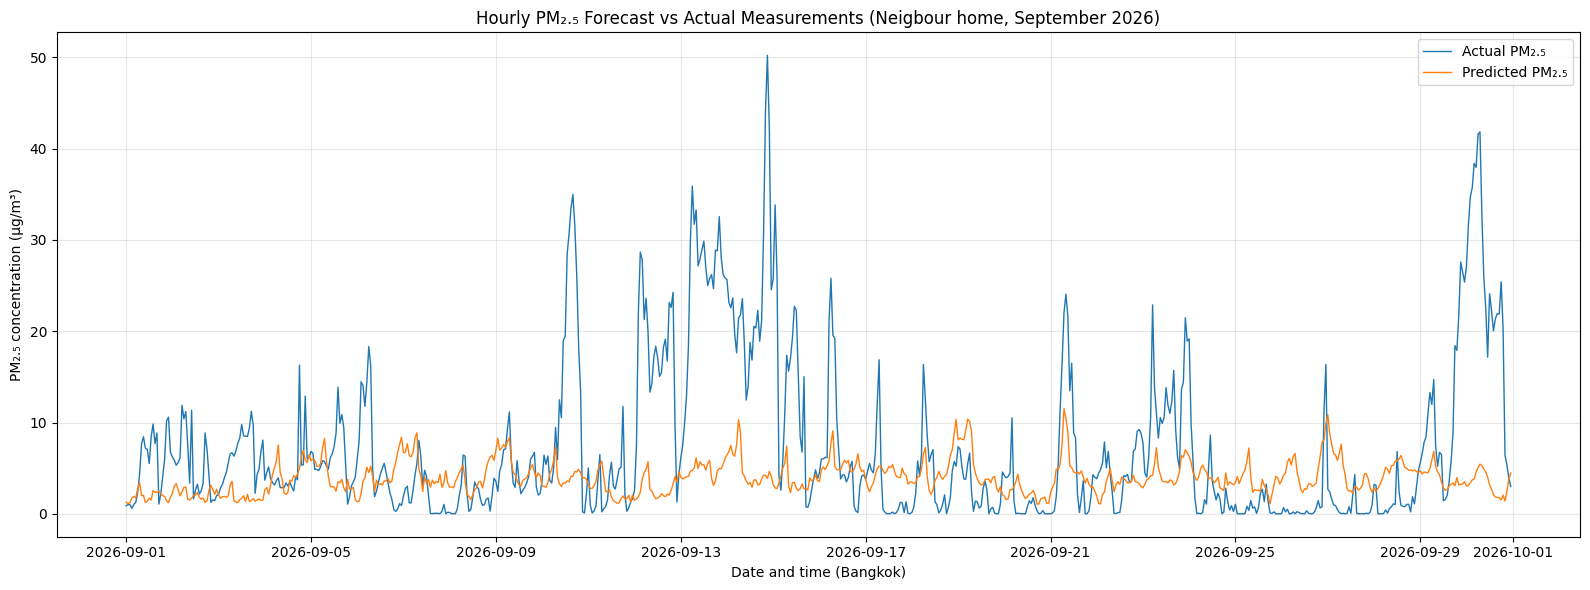

In [ ]:
plt.figure(figsize=(16, 6))

plt.plot(
    comparison["measured_at"],
    comparison["actual_pm25"],
    label="Actual PM₂.₅",
    linewidth=1
)

plt.plot(
    comparison["measured_at"],
    comparison["predicted_pm25"],
    label="Predicted PM₂.₅",
    linewidth=1
)

plt.title(
    f"Hourly PM₂.₅ Forecast vs Actual Measurements "
    f"(Neigbour home, September 2026)"
)

plt.xlabel("Date and time (Bangkok)")
plt.ylabel("PM₂.₅ concentration (µg/m³)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# This section is still in progress, still trying to work/ understand why the model is negative

### This code saves the hourly PM 2.5 prediction comparison and evaluation metrics as CSV files in Windows folder.Then displays the file locations so you can find them easily.






In [ ]:
# Get your Windows user folder automatically
save_folder = Path.home()

# Save the forecast comparison
comparison_path = save_folder / "lightgbm_pm25_forecast_neigbour home_september.csv"
comparison.to_csv(comparison_path, index=False)

# Create the evaluation metrics table
metrics_df = pd.DataFrame({
    "Metric": [
        "Location ID",
        "Forecast frequency",
        "Evaluation period",
        "Hours forecast",
        "Hours evaluated",
        "MAE (µg/m³)",
        "RMSE (µg/m³)",
        "R²"
    ],
    "Value": [
        location_id,
        "Hourly",
        "September 2026",
        len(comparison),
        len(evaluation_data),
        mae,
        rmse,
        r2
    ]
})

# Save the evaluation metrics
metrics_path = save_folder / "lightgbm_pm25_forecast_metrics_neigbour home.csv"
metrics_df.to_csv(metrics_path, index=False)

print("Files saved successfully!")
print("Your Windows user folder:", save_folder)
print("Forecast comparison:", comparison_path)
print("Evaluation metrics:", metrics_path)

Files saved successfully!
Your Windows user folder: /root
Forecast comparison: /root/lightgbm_pm25_forecast_neigbour home_september.csv
Evaluation metrics: /root/lightgbm_pm25_forecast_metrics_neigbour home.csv


### Daily forecast

## This code loads and cleans the PM dataset for Neighbour Home, converts hourly measurements into daily averages, uses data from June to August 2026 to train a LightGBM model, forecasts daily average PM 2.5 concentrations for September 2026, compares the predictions with actual measurements to evaluate forecast accuracy, and saves the results as a CSV file.

### The code takes all the hourly PM₂.₅ readings recorded in a day, adds them together, and divides them by the number of available readings to calculate the daily average PM 2.5 concentration .

In [ ]:

# LOAD THE  DATASET

file_path = Path("new measurements.csv")

df = pd.read_csv(file_path)

print("Original dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# SELECT LOCATION ID 1052(Neighbour home)

df = df[df["location_id"] == 1052].copy()

# Preserve the local clock time in the timestamps.
# This avoids changing the recorded Bangkok measurement hours.
df["measured_at"] = (
    df["measured_at"]
    .astype(str)
    .str.replace(r"[+-]\d{2}:\d{2}$", "", regex=True)
)

df["measured_at"] = pd.to_datetime(
    df["measured_at"],
    errors="coerce"
)

df["pm25_ug_m3"] = pd.to_numeric(
    df["pm25_ug_m3"],
    errors="coerce"
)

df = df.dropna(subset=["measured_at", "pm25_ug_m3"])

df = df.sort_values("measured_at")

print("\nRows for location 1052:", len(df))
print("First measurement:", df["measured_at"].min())
print("Last measurement:", df["measured_at"].max())



#CONVERT HOURLY MEASUREMENTS TO DAILY AVERAGES


df = df.set_index("measured_at")

daily = df["pm25_ug_m3"].resample("D").mean()

daily = daily.asfreq("D")

print("\nDaily dataset:")
print("Number of days:", len(daily))
print("Missing daily averages:", daily.isna().sum())


# SPLIT TRAINING AND TESTING PERIODS

# Training: June 1 to August 31, 2026
train = daily.loc[
    "2026-06-01":"2026-08-31"
].copy()

# Testing: September 1 to September 30, 2026
actual_september = daily.loc[
    "2026-09-01":"2026-09-30"
].copy()

print("\nTraining days:", len(train))
print("September days:", len(actual_september))

print("\nTraining missing values:", train.isna().sum())
print("September missing values:", actual_september.isna().sum())



# HANDLE MISSING DAILY VALUES IN TRAINING DATA

# Interpolate missing values only within the training period.
# September actual measurements are not used for training.

train = train.interpolate(
    method="time",
    limit_area="inside"
)

# Remove any missing values remaining at the beginning or end.
train = train.dropna()

if len(train) < 15:
    raise ValueError(
        "There are too few training days. Check the dataset dates."
    )

if actual_september.isna().any():
    print(
        "\nWARNING: Some September daily averages are missing. "
        "Those dates cannot be evaluated against actual measurements."
    )


# ------------------------------------------------------------
# 6. CREATE FEATURES FOR DAILY FORECASTING
# ------------------------------------------------------------

def create_features(history, date):
    """
    Create features using only observations available before
    the date being forecast.
    """

    date = pd.Timestamp(date)

    return {
        "day_of_week": date.dayofweek,
        "day_of_month": date.day,
        "month": date.month,
        "day_of_year": date.dayofyear,

        # Previous daily measurements
        "lag_1": history.iloc[-1],
        "lag_2": history.iloc[-2],
        "lag_3": history.iloc[-3],
        "lag_7": history.iloc[-7],

        # Recent daily averages
        "rolling_mean_3": history.iloc[-3:].mean(),
        "rolling_mean_7": history.iloc[-7:].mean(),
        "rolling_mean_14": history.iloc[-14:].mean()
    }


feature_columns = [
    "day_of_week",
    "day_of_month",
    "month",
    "day_of_year",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "rolling_mean_3",
    "rolling_mean_7",
    "rolling_mean_14"
]


# PREPARE TRAINING FEATURES


X_train = []
y_train = []

for i in range(14, len(train)):

    history = train.iloc[:i]
    target_date = train.index[i]

    features = create_features(history, target_date)

    X_train.append(features)
    y_train.append(train.iloc[i])

X_train = pd.DataFrame(X_train, columns=feature_columns)
y_train = pd.Series(y_train)

print("\nTraining feature shape:", X_train.shape)


# TRAIN THE LIGHTGBM MODEL

model = LGBMRegressor(
    objective="regression",
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=5,
    random_state=42,
    verbosity=-1
)

model.fit(X_train, y_train)

print("\nLightGBM model training completed.")


# FORECAST SEPTEMBER ONE DAY AT A TIME

# Start with training history.
history = train.copy()

forecast_dates = pd.date_range(
    start="2026-09-01",
    end="2026-09-30",
    freq="D"
)

predictions = []

for date in forecast_dates:

    features = create_features(history, date)

    X_future = pd.DataFrame(
        [features],
        columns=feature_columns
    )

    predicted_value = model.predict(X_future)[0]

    # PM2.5 concentration cannot be negative.
    predicted_value = max(0, predicted_value)

    predictions.append(predicted_value)

    # Add the prediction to history so it can be used
    # when forecasting the following day.
    history.loc[date] = predicted_value


# CREATE THE RESULTS TABLE

forecast = pd.DataFrame({
    "date": forecast_dates,
    "predicted_pm25": predictions
})

forecast["actual_pm25"] = forecast["date"].map(
    actual_september.to_dict()
)

forecast["error"] = (
    forecast["predicted_pm25"] - forecast["actual_pm25"]
)

forecast["absolute_error"] = forecast["error"].abs()

print("\nDaily forecast results:")
display(forecast.round(3))


#CALCULATE FORECAST ACCURACY

evaluation = forecast.dropna(
    subset=["actual_pm25", "predicted_pm25"]
).copy()

if len(evaluation) == 0:

    print("\nNo matching actual September values for evaluation.")

else:

    mae = mean_absolute_error(
        evaluation["actual_pm25"],
        evaluation["predicted_pm25"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            evaluation["actual_pm25"],
            evaluation["predicted_pm25"]
        )
    )

    print("\nDAILY FORECAST ACCURACY")
    print("-----------------------")
    print("Days evaluated:", len(evaluation))
    print(f"MAE:  {mae:.3f} µg/m³")
    print(f"RMSE: {rmse:.3f} µg/m³")

    if len(evaluation) >= 2:
        r2 = r2_score(
            evaluation["actual_pm25"],
            evaluation["predicted_pm25"]
        )
        print(f"R²:   {r2:.3f}")
    else:
        print("R²: Not calculated because fewer than two days are available.")


# SAVE THE RESULTS AS A CSV FILE


save_path = (
    Path.home() /
    "lightgbm_daily_pm25_forecast at neigbour home september.csv"
)

forecast.to_csv(save_path, index=False)

print("\nForecast saved to:")
print(save_path)

Original dataset shape: (38064, 4)
Columns: ['location_id', 'measured_at', 'pm25_ug_m3', 'sample_count']

Rows for location 1052: 2927
First measurement: 2026-06-01 00:00:00
Last measurement: 2026-09-30 23:00:00

Daily dataset:
Number of days: 122
Missing daily averages: 0

Training days: 92
September days: 30

Training missing values: 0
September missing values: 0

Training feature shape: (78, 11)

LightGBM model training completed.

Daily forecast results:


,date,predicted_pm25,actual_pm25,error,absolute_error
0,2026-09-01,3.434,5.164,-1.730,1.730
1,2026-09-02,3.917,5.282,-1.365,1.365
2,2026-09-03,4.838,6.520,-1.682,1.682
3,2026-09-04,4.448,4.794,-0.346,0.346
4,2026-09-05,3.254,6.103,-2.850,2.850
5,2026-09-06,2.638,6.077,-3.439,3.439
6,2026-09-07,2.785,2.190,0.595,0.595
7,2026-09-08,2.472,1.903,0.569,0.569
8,2026-09-09,2.472,4.737,-2.265,2.265
9,2026-09-10,1.521,13.744,-12.223,12.223



DAILY FORECAST ACCURACY
-----------------------
Days evaluated: 30
MAE:  5.364 µg/m³
RMSE: 8.409 µg/m³
R²:   -0.482

Forecast saved to:
/root/lightgbm_daily_pm25_forecast at neigbour home september.csv


### This code creates a line graph comparing the actual daily average PM 2.5 measurements with the values predicted by the LightGBM model for Neighbour Home in September 2026.

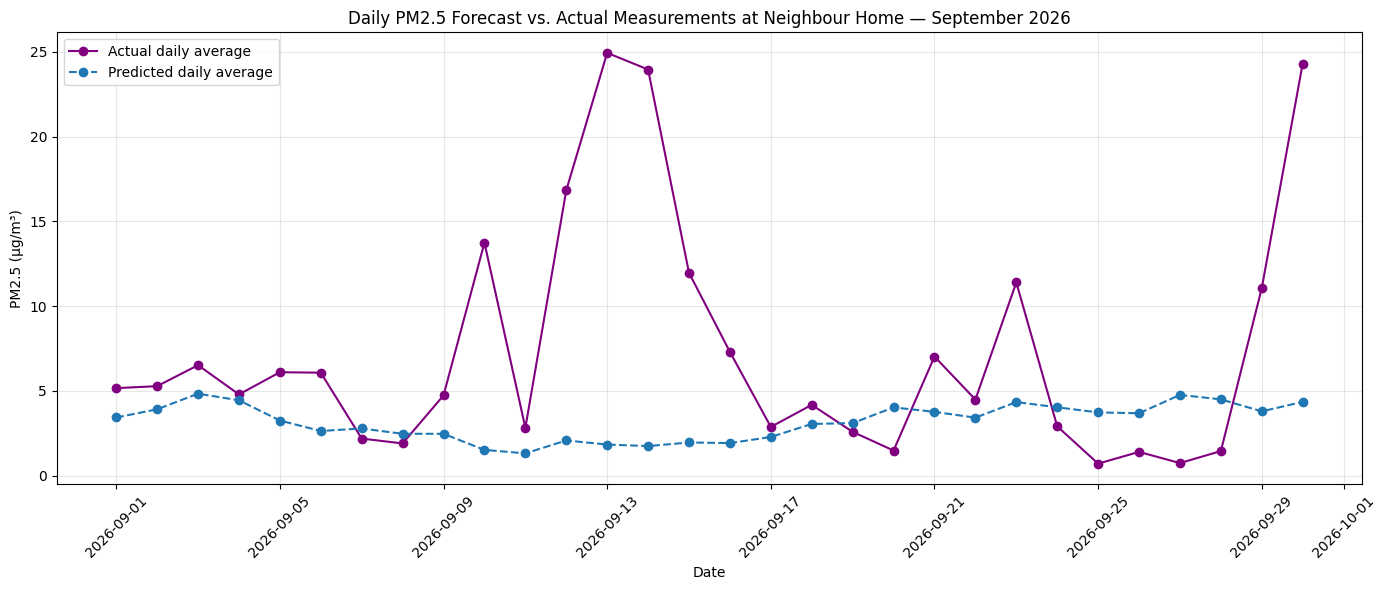

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    forecast["date"],
    forecast["actual_pm25"],
    marker="o",
    color="purple",
    label="Actual daily average")

plt.plot(
    forecast["date"],
    forecast["predicted_pm25"],
    marker="o",
    linestyle="--",
    label="Predicted daily average"
)

plt.title("Daily PM2.5 Forecast vs. Actual Measurements at Neighbour Home — September 2026")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Still trying to understand this

Original dataset rows: 38064
Location ID: 1052
First timestamp: 2026-06-01 00:00:00
Last timestamp: 2026-09-30 23:00:00
Missing hourly values: 1

Complete 24-hour periods: 120
All periods contain 24 hourly readings: True


,period_start,period_end,actual_pm25_24h_average,hourly_readings
0,2026-06-01 14:00:00,2026-06-02 14:00:00,18.220758,24
1,2026-06-02 14:00:00,2026-06-03 14:00:00,8.266654,24
2,2026-06-03 14:00:00,2026-06-04 14:00:00,3.329094,24
3,2026-06-04 14:00:00,2026-06-05 14:00:00,0.767235,24
4,2026-06-05 14:00:00,2026-06-06 14:00:00,0.972984,24



Training periods: 90
September forecast periods: 30

Training feature shape: (83, 9)
LightGBM training completed.

Forecast results:


,period_start,period_end,predicted_pm25_24h_average,actual_pm25_24h_average,error,absolute_error
0,2026-09-01 14:00:00,2026-09-02 14:00:00,1.583,6.646,-5.063,5.063
1,2026-09-02 14:00:00,2026-09-03 14:00:00,0.732,4.889,-4.158,4.158
2,2026-09-03 14:00:00,2026-09-04 14:00:00,0.983,5.142,-4.159,4.159
3,2026-09-04 14:00:00,2026-09-05 14:00:00,1.876,6.202,-4.327,4.327
4,2026-09-05 14:00:00,2026-09-06 14:00:00,1.843,7.841,-5.998,5.998
5,2026-09-06 14:00:00,2026-09-07 14:00:00,1.576,2.974,-1.399,1.399
6,2026-09-07 14:00:00,2026-09-08 14:00:00,1.576,1.194,0.382,0.382
7,2026-09-08 14:00:00,2026-09-09 14:00:00,0.892,3.882,-2.990,2.990
8,2026-09-09 14:00:00,2026-09-10 14:00:00,0.925,7.430,-6.505,6.505
9,2026-09-10 14:00:00,2026-09-11 14:00:00,1.351,9.347,-7.996,7.996



24-HOUR FORECAST METRICS
------------------------
Periods evaluated: 29
MAE:  6.186 µg/m³
RMSE: 8.925 µg/m³
R²:   -0.778


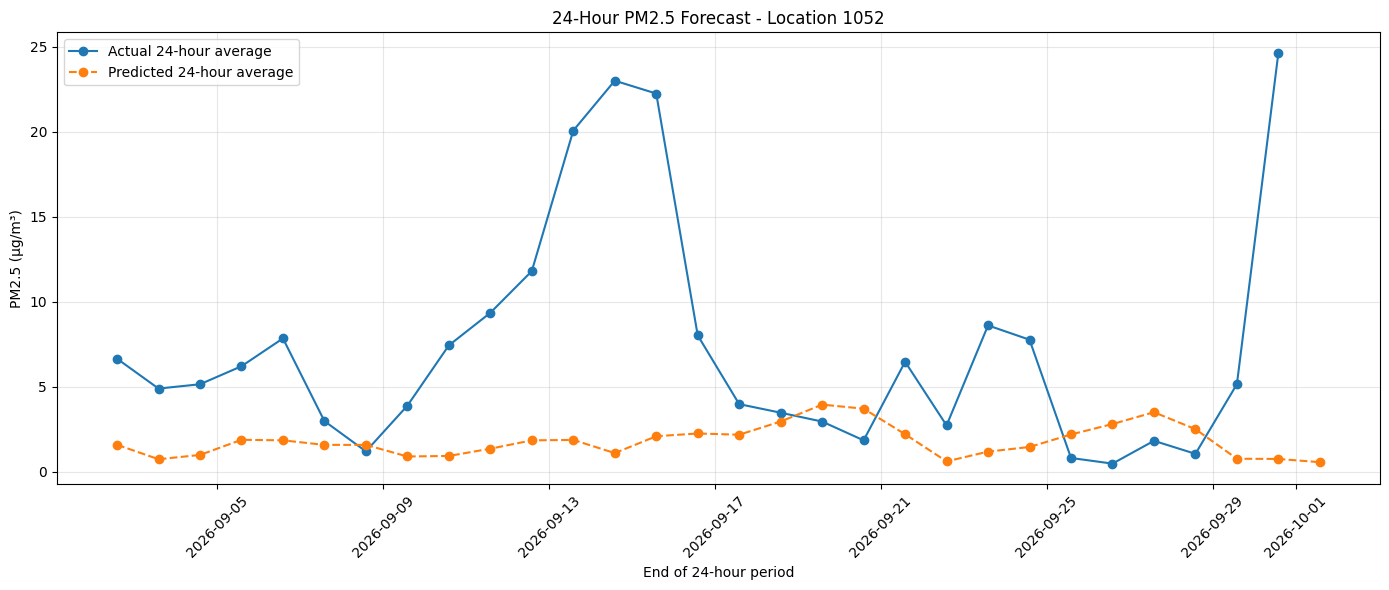


Forecast saved to:
/root/lightgbm_24h_pm25_forecast_location_1052_september.csv


In [ ]:
# ============================================================
# LIGHTGBM 24-HOUR PM2.5 FORECAST
# Location ID: 1052
# Training: June-August 2026
# Forecasting: September 2026
# Each window: 2 PM to 2 PM the following day
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

file_path = Path("new measurements.csv")

df = pd.read_csv(file_path)

print("Original dataset rows:", len(df))


# ------------------------------------------------------------
# 2. FILTER LOCATION 1052 AND PREPARE TIMESTAMPS
# ------------------------------------------------------------

df = df[df["location_id"] == 1052].copy()

# Preserve the recorded Bangkok local clock time.
df["measured_at"] = (
    df["measured_at"]
    .astype(str)
    .str.replace(r"[+-]\d{2}:\d{2}$", "", regex=True)
)

df["measured_at"] = pd.to_datetime(
    df["measured_at"],
    errors="coerce"
)

df["pm25_ug_m3"] = pd.to_numeric(
    df["pm25_ug_m3"],
    errors="coerce"
)

df = df.dropna(subset=["measured_at", "pm25_ug_m3"])

# Average duplicate measurements, if any, at the same timestamp.
hourly_pm25 = (
    df.groupby("measured_at")["pm25_ug_m3"]
    .mean()
    .sort_index()
)

# Build a complete hourly index.
hourly_pm25 = hourly_pm25.asfreq("h")

print("Location ID: 1052")
print("First timestamp:", hourly_pm25.index.min())
print("Last timestamp:", hourly_pm25.index.max())
print("Missing hourly values:", hourly_pm25.isna().sum())


# ------------------------------------------------------------
# 3. AGGREGATE INTO EXACT 24-HOUR WINDOWS
# ------------------------------------------------------------

# Each window includes its start and excludes its end.
# Example:
# September 1, 2 PM to September 2, 2 PM.
#
# The end timestamp labels each window.

period_ends = pd.date_range(
    start="2026-06-02 14:00:00",
    end="2026-10-01 14:00:00",
    freq="24h"
)

results = []

for period_end in period_ends:

    period_start = period_end - pd.Timedelta(hours=24)

    window = hourly_pm25.loc[
        (hourly_pm25.index >= period_start) &
        (hourly_pm25.index < period_end)
    ]

    # Keep only periods with 24 valid hourly readings.
    if len(window) == 24 and window.notna().all():

        results.append({
            "period_start": period_start,
            "period_end": period_end,
            "actual_pm25_24h_average": window.mean(),
            "hourly_readings": len(window)
        })

daily_24h = pd.DataFrame(results)

if daily_24h.empty:
    raise ValueError(
        "No complete 24-hour periods found. Check the timestamps "
        "and availability of hourly measurements."
    )

print("\nComplete 24-hour periods:", len(daily_24h))

print(
    "All periods contain 24 hourly readings:",
    (daily_24h["hourly_readings"] == 24).all()
)

display(daily_24h.head())


# ------------------------------------------------------------
# 4. SPLIT TRAINING AND SEPTEMBER DATA
# ------------------------------------------------------------

daily_24h = daily_24h.set_index("period_end").sort_index()

# Training: periods ending June 2 through August 31 at 2 PM.
train = daily_24h.loc[
    "2026-06-02 14:00:00":"2026-08-31 14:00:00",
    "actual_pm25_24h_average"
].copy()

# Actual September windows:
# Start September 1 at 2 PM; end October 1 at 2 PM.
september_actual = daily_24h.loc[
    "2026-09-02 14:00:00":"2026-10-01 14:00:00",
    "actual_pm25_24h_average"
].copy()

forecast_dates = pd.date_range(
    start="2026-09-02 14:00:00",
    end="2026-10-01 14:00:00",
    freq="24h"
)

print("\nTraining periods:", len(train))
print("September forecast periods:", len(forecast_dates))


# ------------------------------------------------------------
# 5. HANDLE MISSING VALUES IN TRAINING DATA
# ------------------------------------------------------------

# Interpolate internal missing training periods only.
train = train.interpolate(
    method="time",
    limit_area="inside"
).dropna()

if len(train) < 15:
    raise ValueError(
        "Insufficient training periods. Check the data."
    )


# ------------------------------------------------------------
# 6. CREATE FEATURES
# ------------------------------------------------------------

def create_features(history, target_date):

    target_date = pd.Timestamp(target_date)

    return {
        "day_of_week": target_date.dayofweek,
        "day_of_month": target_date.day,
        "month": target_date.month,

        "lag_1": history.iloc[-1],
        "lag_2": history.iloc[-2],
        "lag_3": history.iloc[-3],
        "lag_7": history.iloc[-7],

        "rolling_mean_3": history.iloc[-3:].mean(),
        "rolling_mean_7": history.iloc[-7:].mean()
    }


feature_columns = [
    "day_of_week",
    "day_of_month",
    "month",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "rolling_mean_3",
    "rolling_mean_7"
]


# ------------------------------------------------------------
# 7. PREPARE TRAINING FEATURES
# ------------------------------------------------------------

X_train = []
y_train = []

for i in range(7, len(train)):

    history = train.iloc[:i]
    target_date = train.index[i]

    X_train.append(
        create_features(history, target_date)
    )

    y_train.append(train.iloc[i])

X_train = pd.DataFrame(
    X_train,
    columns=feature_columns
)

y_train = pd.Series(y_train)

print("\nTraining feature shape:", X_train.shape)


# ------------------------------------------------------------
# 8. TRAIN LIGHTGBM
# ------------------------------------------------------------

model = LGBMRegressor(
    objective="regression",
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=5,
    random_state=42,
    verbosity=-1
)

model.fit(X_train, y_train)

print("LightGBM training completed.")


# ------------------------------------------------------------
# 9. FORECAST SEPTEMBER
# ------------------------------------------------------------

# Begin with historical training data.
history = train.copy()

predictions = []

for target_date in forecast_dates:

    features = create_features(
        history,
        target_date
    )

    X_future = pd.DataFrame(
        [features],
        columns=feature_columns
    )

    predicted_value = model.predict(X_future)[0]

    # PM2.5 concentration cannot be negative.
    predicted_value = max(0, predicted_value)

    predictions.append(predicted_value)

    # Use the prediction for the next forecast period.
    history.loc[target_date] = predicted_value


# ------------------------------------------------------------
# 10. CREATE FORECAST TABLE
# ------------------------------------------------------------

forecast = pd.DataFrame({
    "period_start": forecast_dates - pd.Timedelta(hours=24),
    "period_end": forecast_dates,
    "predicted_pm25_24h_average": predictions
})

# Match actual values using the same period-end timestamp.
actual_lookup = daily_24h["actual_pm25_24h_average"]

forecast["actual_pm25_24h_average"] = (
    forecast["period_end"]
    .map(actual_lookup)
)

forecast["error"] = (
    forecast["predicted_pm25_24h_average"]
    - forecast["actual_pm25_24h_average"]
)

forecast["absolute_error"] = forecast["error"].abs()

print("\nForecast results:")
display(forecast.round(3))


# ------------------------------------------------------------
# 11. EVALUATE FORECAST ACCURACY
# ------------------------------------------------------------

evaluation = forecast.dropna(
    subset=[
        "actual_pm25_24h_average",
        "predicted_pm25_24h_average"
    ]
)

if len(evaluation) > 0:

    mae = mean_absolute_error(
        evaluation["actual_pm25_24h_average"],
        evaluation["predicted_pm25_24h_average"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            evaluation["actual_pm25_24h_average"],
            evaluation["predicted_pm25_24h_average"]
        )
    )

    print("\n24-HOUR FORECAST METRICS")
    print("------------------------")
    print("Periods evaluated:", len(evaluation))
    print(f"MAE:  {mae:.3f} µg/m³")
    print(f"RMSE: {rmse:.3f} µg/m³")

    if len(evaluation) >= 2:
        r2 = r2_score(
            evaluation["actual_pm25_24h_average"],
            evaluation["predicted_pm25_24h_average"]
        )
        print(f"R²:   {r2:.3f}")

else:
    print("No matching actual values available for evaluation.")


# ------------------------------------------------------------
# 12. PLOT ACTUAL VS PREDICTED PM2.5
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    forecast["period_end"],
    forecast["actual_pm25_24h_average"],
    marker="o",
    label="Actual 24-hour average"
)

plt.plot(
    forecast["period_end"],
    forecast["predicted_pm25_24h_average"],
    marker="o",
    linestyle="--",
    label="Predicted 24-hour average"
)

plt.title("24-Hour PM2.5 Forecast - Location 1052")

plt.xlabel("End of 24-hour period")
plt.ylabel("PM2.5 (µg/m³)")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. SAVE FORECAST RESULTS
# ------------------------------------------------------------

save_path = (
    Path.home()
    / "lightgbm_24h_pm25_forecast_location_1052_september.csv"
)

forecast.to_csv(
    save_path,
    index=False
)

print("\nForecast saved to:")
print(save_path)